## Example

In [2]:
import numpy as np
import pandas as pd

a = pd.read_csv(
    r'D:\quant_learning\data\pandas_exercises\09_Time_Series\Apple_Stock\appl_1980_2014.csv',
    parse_dates=['Date']
)
a = a.sort_values('Date').reset_index(drop=True)
close = a['Adj Close']

In [3]:
close
close.shift(1)
close.diff()

ret_simple = close.pct_change()
ret_log = np.log(close/close.shift(1))


In [4]:
ma5 = close.rolling(5).mean()
ma20 = close.rolling(20).mean()
vol20 = ret_log.rolling(20).std()*np.sqrt(252)
hi20 = close.rolling(20).max()
lo20 = close.rolling(20).min()

In [5]:
close.expanding().mean()
ema20 = close.ewm(span=20,adjust=False).mean()

In [6]:
delta = close.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()
rsi14 = 100 - 100/(1+avg_gain/avg_loss)


In [7]:
cross = (close > ma20) & (close.shift(1) <= ma20.shift(1))
nav = np.exp(ret_log.cumsum())

## Exercise

In [8]:

a = pd.read_csv(
    r'D:\quant_learning\data\pandas_exercises\09_Time_Series\Apple_Stock\appl_1980_2014.csv',
    parse_dates=['Date']
)

a = a.sort_values('Date').set_index('Date')

close = a['Adj Close']
print(close.iloc[-1])
ma5 = close.rolling(5).mean()
print(ma5.iloc[-1])
ma20 = close.rolling(20).mean()
print(ma20.iloc[-1])
ema20 = close.ewm(span=20,adjust=False).mean()
print(ema20.iloc[-1])
ret_log = np.log(close/close.shift(1))
vol20 = ret_log.rolling(20).std()*np.sqrt(252)
print(vol20.iloc[-1])
mom20 = close/close.shift(20) - 1
print(mom20.iloc[-1])
delta = close - close.shift()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()
rsi14 = 100 - 100*avg_loss/(avg_gain+avg_loss)
print(rsi14.iloc[-1])
hi20 = close.rolling(20).max()
print(hi20.iloc[-1])
lo20 = close.rolling(20).min()
print(lo20.iloc[-1])
nav = np.exp(ret_log.cumsum())
print(nav.iloc[-1])


95.35
94.47
92.527
92.44152983744515
0.14190174801361585
0.017609391675560193
69.48748510131105
95.97
90.28
211.88888888888678


In [9]:
print(close['2014-06-02'])
print(ma20['2014-06-02'])
print(rsi14['2014-06-02'])
cross = (close > ma20) & (close.shift(1) <= ma20.shift(1))
print(cross.sum())

89.81
86.4415
78.57142857142867
492


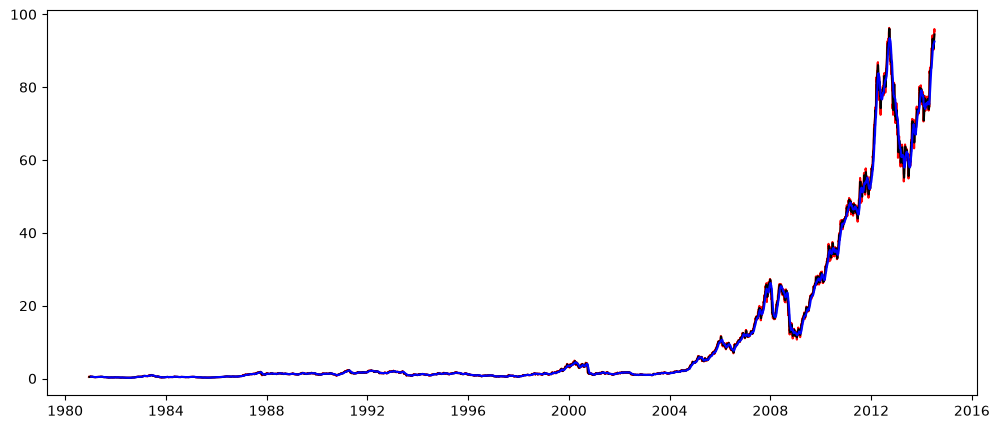

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(close,color='red')
plt.plot(ma5,color='black')
plt.plot(ma20,color='blue')
plt.show()